In [1]:
import pandas as pd
import pickle
import numpy as np
from datetime import datetime, timedelta
import os
from utils.geoutil import StatePolygon, CountyPolygon, FIPS_list
import geopandas as gpd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from scipy import stats
from matplotlib import colors
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.pyplot as plt
import numpy as np
from utils.Visualizations import plotComparisonIntercept
from utils.metrics import MB, RMSE, FB, FE, pearson_r, NMSE, COD
import pyproj
from utils.ZonalStats import polygon_statistics
from utils.utils import build_kdtree, findSpatialIndex_kdtree
from sklearn.metrics import r2_score

In [2]:
from utils.geoutil import StatePolygon, FIPS_list

epa_regions = {
    1: {
        "name": "New England",
        "headquarters": "Boston",
        "states": ["Connecticut", "Maine", "Massachusetts", "New Hampshire", "Rhode Island", "Vermont"]
    },
    2: {
        "name": "New York",
        "headquarters": "New York City",
        "states": ["New Jersey", "New York"]
    },
    3: {
        "name": "Mid-Atlantic",
        "headquarters": "Philadelphia",
        "states": ["Delaware", "District of Columbia", "Maryland", "Pennsylvania", "Virginia", "West Virginia"]
    },
    4: {
        "name": "Southeast",
        "headquarters": "Atlanta",
        "states": ["Alabama", "Florida", "Georgia", "Kentucky", "Mississippi", "North Carolina", "South Carolina", "Tennessee"]
    },
    5: {
        "name": "Great Lakes",
        "headquarters": "Chicago",
        "states": ["Illinois", "Indiana", "Michigan", "Minnesota", "Ohio", "Wisconsin"]
    },
    6: {
        "name": "South Central",
        "headquarters": "Dallas",
        "states": ["Arkansas", "Louisiana", "New Mexico", "Oklahoma", "Texas"]
    },
    7: {
        "name": "Midwest",
        "headquarters": "Kansas City",
        "states": ["Iowa", "Kansas", "Missouri", "Nebraska"]
    },
    8: {
        "name": "Mountains and Plains",
        "headquarters": "Denver",
        "states": ["Colorado", "Montana", "North Dakota", "South Dakota", "Utah", "Wyoming"]
    },
    9: {
        "name": "Pacific Southwest",
        "headquarters": "San Francisco",
        "states": ["Arizona", "California", "Nevada"]
    },
    10: {
        "name": "Pacific Northwest",
        "headquarters": "Seattle",
        "states": ["Idaho", "Oregon", "Washington"]
    }
}

In [3]:
fire_checks = {
    9: [datetime(2021, 8, 1), datetime(2021, 8, 31)],
    6: [datetime(2022, 5, 1), datetime(2022, 5, 31)],
    10: [datetime(2023, 9, 1), datetime(2023, 9, 30)],
    10: [datetime(2024, 8, 1), datetime(2023, 8, 1)],
}
start_time = datetime(2023, 9, 1)
end_time = datetime(2023, 9, 30)
region_numbers = [10]
states = []
for n in region_numbers:
    states.extend(epa_regions[n]["states"])
metrics_dict = {
    "MB": {"func": MB},
    "RMSE": {"func": RMSE},
    "corr": {"func": pearson_r},
}
states_polys = StatePolygon(states)
state_ids = FIPS_list(states)
county_ids, county_polygons = CountyPolygon(states)
state_geom_dict  = dict(zip(state_ids, states_polys))
county_geom_dict = dict(zip(county_ids, county_polygons))

# Model Indexes in Plygons

In [4]:
# modeled stats info
static_file = "/Users/zongrunli/Desktop/SmkFcstEval/data/fcst_data/static/aqm_static.npz"
file_folder = "/Volumes/T9/UFSAQM/Evaluation/values"
static_info = np.load(static_file)
lon, lat = static_info["lon"], static_info["lat"]
x, y = static_info["x"], static_info["y"]
crs_proj4 = static_info["crs_proj4"].item()
crs = pyproj.Proj(crs_proj4)
DX = x[0, 1] - x[0, 0]
DY = y[1, 0] - y[0, 0]
tree = build_kdtree(x, y)
tree_lonlat = build_kdtree(lon, lat)
model_info = {"crs": crs, "DX": DX, "DY": DY, "tree": tree, "X_ctr": x, "Y_ctr": y}
lon_min, lon_max = np.min(lon), np.max(lon)
lat_min, lat_max = np.min(lat), np.max(lat)
state_portion_lists = polygon_statistics(model_info, states_polys)

all_indices = set()
for portion_list in state_portion_lists:
    for (i, j, portion) in portion_list:
        if portion > 0:
            all_indices.add((i, j))
rows = np.array([idx[0] for idx in all_indices])
cols = np.array([idx[1] for idx in all_indices])

df_region = []
for filename in sorted(os.listdir(file_folder)):
    cur_path = os.path.join(file_folder, filename)
    cur_values = np.load(cur_path)
    cur_time = cur_values["time"][0:24]
    time_datetime = pd.to_datetime(cur_time, unit="s").to_pydatetime().tolist()
    cur_pm = cur_values["PM25_UFSAQM"][0:24, :, :]
    pm_region = cur_pm[:, rows, cols]
    p25 = np.nanpercentile(pm_region, 25, axis=1)
    p75 = np.nanpercentile(pm_region, 75, axis=1)
    cur_df_region = pd.DataFrame({
        "Time": time_datetime,
        "p25": p25,
        "p75": p75,
    })
    df_region.append(cur_df_region)
df_region = pd.concat(df_region).reset_index(drop=True)

In [5]:
stn_locs_file = "/Users/zongrunli/Desktop/ForecastEvaluation/data/static/stn_info.pkl"
obs_file = "/Users/zongrunli/Desktop/ForecastEvaluation/data/obs/PM25_obs_2021_2024.csv"
stats_folder = "/Users/zongrunli/Desktop/ForecastEvaluation/data/eval_data/UFSAQM_RAW_NEW/site_levels/06"
with open(stn_locs_file, 'rb') as file:
    site_dict = pickle.load(file)

obs_df = pd.read_csv(obs_file, parse_dates=["Time"], dtype={"siteCode": str})
obs_df = obs_df[(obs_df["Time"] >= start_time) & (obs_df["Time"] <  end_time)]
obs_df["stateCode"]  = obs_df["siteCode"].str[:2]
obs_df["countyCode"] = obs_df["siteCode"].str[:5]

In [6]:
cur_time = start_time
model_list  = []
while cur_time < end_time:
    date_str = cur_time.strftime("%Y%m%d")
    cur_model_file  = os.path.join(stats_folder, f"site_level_aqm_{date_str}_06.csv")
    if os.path.exists(cur_model_file):
        model_list.append(pd.read_csv(cur_model_file, parse_dates=["Time"], dtype={"siteCode": str}))
    cur_time += timedelta(days=1)
model_df  = pd.concat(model_list,  ignore_index=True)
merged_df = model_df.merge(obs_df[["siteCode", "Time", "PM25"]], on=["siteCode", "Time"], how="inner")

In [7]:
merged_df["stateCode"]  = merged_df["siteCode"].str[:2]
merged_df = merged_df[merged_df["stateCode"].isin(state_ids)]

In [8]:
merged_df_avg = merged_df.groupby("Time")[["PM25", "PM25_UFSAQM"]].mean().reset_index()

# Hourly spread of the observations across all stations (P25 / P75)
obs_pct = (
    merged_df.groupby("Time")["PM25"]
    .quantile([0.25, 0.75])
    .unstack()
    .rename(columns={0.25: "obs_p25", 0.75: "obs_p75"})
    .reset_index()
)
merged_df_avg = merged_df_avg.merge(obs_pct, on="Time", how="left")

# Calculate Region Averaged

In [9]:
merged_df_avg = merged_df_avg.rename(columns={"PM25_UFSAQM": "PM25_UFSAQM_stn_avg"})
merged = merged_df_avg.merge(df_region, on="Time", how="inner")

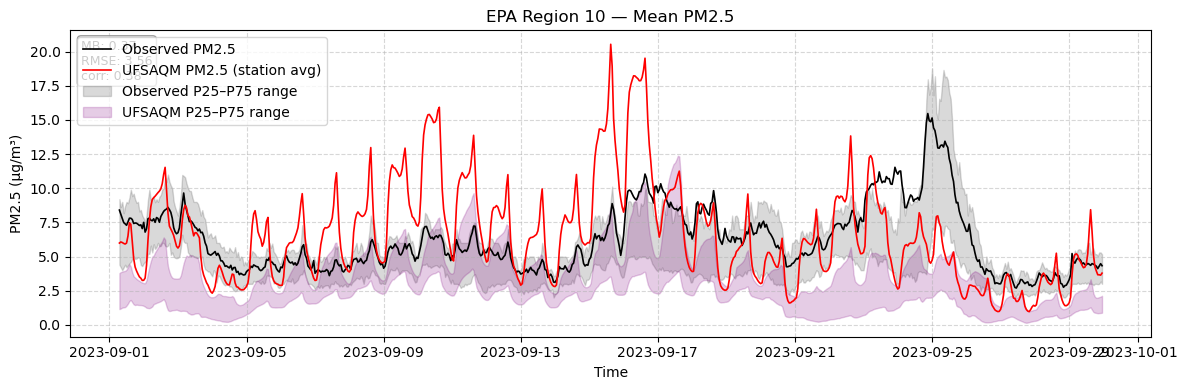

In [10]:
pred = merged["PM25_UFSAQM_stn_avg"].values
obs  = merged["PM25"].values
metrics_label = "\n".join(
    f"{name}: {info['func'](pred, obs):.2f}"
    for name, info in metrics_dict.items()
)


fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(merged["Time"], merged["PM25"],                  color="black",  linewidth=1.2, label="Observed PM2.5")
ax.plot(merged["Time"], merged["PM25_UFSAQM_stn_avg"],   color="red",    linewidth=1.2, label="UFSAQM PM2.5 (station avg)")
# ax.plot(merged["Time"], merged["PM25_UFSAQM_state_avg"], color="purple", linewidth=1.2, label="State UFSAQM PM2.5")
ax.fill_between(merged["Time"], merged["obs_p25"], merged["obs_p75"],
                color="black", alpha=0.15, label="Observed P25–P75 range")
ax.fill_between(merged["Time"], merged["p25"], merged["p75"],
                color="purple", alpha=0.2, label="UFSAQM P25–P75 range")

# metrics as text box
ax.text(0.01, 0.97, metrics_label,
        transform=ax.transAxes,
        fontsize=9, verticalalignment="top",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="gray", alpha=0.8))

if len(region_numbers) == 1:
    region_name = str(region_numbers[0])
else:
    region_name = ", ".join(str(r) for r in region_numbers)

ax.set_title(f"EPA Region {region_name} — Mean PM2.5")
ax.set_xlabel("Time")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.5)
fig.tight_layout()
# plt.savefig(f"{region_name}.png")